# Đặc trưng RFM và baseline luật — Huy

Đồ án đề tài 15, nhóm 4 người — Trường Đại học Sài Gòn, GV Đỗ Như Tài. Dữ liệu: UCI Online Retail (01/12/2010–09/12/2011).

**Mục tiêu tuần 2:** (1) chia dữ liệu theo thời gian tại `CUTOFF = 2011-09-09` và tạo nhãn kiểm chứng; (2) dựng hai bộ đặc trưng `RFM` và `RFM_PLUS` theo khách chỉ từ giai đoạn quan sát; (3) log1p + `StandardScaler` fit trên giai đoạn quan sát; (4) kiểm tra tương quan và dư thừa; (5) phân khúc baseline theo luật RFM (điểm 1–5 theo phân vị) và đo bằng **cùng metric nội tại** sẽ dùng cho mô hình học máy ở tuần sau.

**Phạm vi:** notebook này **không huấn luyện** K-Means, Hierarchical hay DBSCAN.

**Kiểm soát data leakage (tóm tắt, kiểm tra tự động ở mục 8):**

- Mọi đặc trưng, quyết định log1p, scaler và điểm phân vị baseline đều chỉ dùng giao dịch **trước** `CUTOFF`.
- Giao dịch từ `CUTOFF` trở đi chỉ tạo hai cột kiểm chứng `FutureSpend`, `Returned` (lưu riêng ở `future_outcome.csv`). Hai cột này không bao giờ là đặc trưng và không dùng để chọn luật, tham số hay mô hình.
- Trong notebook này **không có chỗ nào đọc `FutureSpend`/`Returned` để ra quyết định**. Các luật ghép phân khúc ở mục 6 được viết ra từ ý nghĩa kinh doanh của R và FM, không chỉnh theo kết quả tương lai.

In [1]:
from pathlib import Path
import sys

# Hỗ trợ chạy từ thư mục gốc hoặc notebooks/.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.config import (SEED, CUTOFF, REF_DATE, RFM, RFM_PLUS, FEATURE_SETS,
                        DATA_PROCESSED, MODELS_DIR, TABLES_DIR, FIGURES_DIR, TUNING_SCHEMA)
from src.data_loader import load_raw
from src.cleaning import clean_transactions
from src import features as ft, baseline as bl, viz_features as vz

np.random.seed(SEED)  # tuần này không có bước ngẫu nhiên nào ngoài mẫu tham chiếu ở mục 7
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
for d in (DATA_PROCESSED, TABLES_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("ROOT =", ROOT, "| SEED =", SEED, "| CUTOFF =", CUTOFF)

ROOT = c:\Users\Admin\machine_learning\DoAn | SEED = 42 | CUTOFF = 2011-09-09


## 1. Làm sạch và chia theo thời gian

Dùng `clean_transactions()` của Quốc Anh (không sửa), rồi `split_by_time()`:

- **Giai đoạn quan sát** = giao dịch có `InvoiceDate < CUTOFF`. Đây là nơi duy nhất được tạo đặc trưng và fit scaler.
- **Giai đoạn kiểm chứng** = `InvoiceDate >= CUTOFF`. Chỉ dùng cho nhãn đánh giá ngoài.
- **Tập phân khúc** = các khách có **ít nhất 1 giao dịch bán** trong giai đoạn quan sát. Khách chỉ xuất hiện sau `CUTOFF` (khách mới) không có đặc trưng nên không được phân khúc; khách chỉ có hóa đơn hủy trong giai đoạn quan sát cũng không có Recency/Frequency/Monetary nên bị loại khỏi tập này.

Dùng `load_raw(use_cache=False)` để Restart & Run All đọc lại Excel, không dính cache cũ.

In [ ]:
raw = load_raw(use_cache=False)
sales, cancel, clean_log = clean_transactions(raw)
sales_obs, cancel_obs, sales_future = ft.split_by_time(sales, cancel, CUTOFF)

cut = pd.Timestamp(CUTOFF)
assert sales_obs.InvoiceDate.max() < cut <= sales_future.InvoiceDate.min()
assert cancel_obs.InvoiceDate.max() < cut
assert len(sales_obs) + len(sales_future) == len(sales)

seg_ids = pd.Index(sorted(sales_obs.CustomerID.unique()), name="CustomerID")
future_customers = set(sales_future.CustomerID.unique())
cancel_only = set(cancel_obs.CustomerID.unique()) - set(seg_ids)

summary = pd.DataFrame({
    "dòng bán": [len(sales_obs), len(sales_future)],
    "hóa đơn bán": [sales_obs.InvoiceNo.nunique(), sales_future.InvoiceNo.nunique()],
    "khách có giao dịch bán": [sales_obs.CustomerID.nunique(), sales_future.CustomerID.nunique()],
    "từ": [sales_obs.InvoiceDate.min(), sales_future.InvoiceDate.min()],
    "đến": [sales_obs.InvoiceDate.max(), sales_future.InvoiceDate.max()],
}, index=["Quan sát (< CUTOFF)", "Kiểm chứng (>= CUTOFF)"])
display(summary)S
print(f"Tập phân khúc: {len(seg_ids):,} khách")
print(f"Khách chỉ xuất hiện ở giai đoạn kiểm chứng (khách mới, không phân khúc): {len(future_customers - set(seg_ids)):,}")
print(f"Khách chỉ có hóa đơn hủy ở giai đoạn quan sát (không có giao dịch bán, không phân khúc): {len(cancel_only):,}")

,dòng bán,hóa đơn bán,khách có giao dịch bán,từ,đến
Quan sát (< CUTOFF),231630,11770,3360,2010-12-01 08:26:00,2011-09-08 19:58:00
Kiểm chứng (>= CUTOFF),159523,6632,2893,2011-09-09 08:48:00,2011-12-09 12:50:00


Tập phân khúc: 3,360 khách
Khách chỉ xuất hiện ở giai đoạn kiểm chứng (khách mới, không phân khúc): 974
Khách chỉ có hóa đơn hủy ở giai đoạn quan sát (không có giao dịch bán, không phân khúc): 34


## 2. Nhãn kiểm chứng (chỉ để đánh giá ngoài RQ3)

Với mỗi khách trong tập phân khúc, tính từ giai đoạn kiểm chứng:

- `FutureSpend`: tổng `Quantity × UnitPrice` của các dòng bán sau `CUTOFF`, bằng 0 nếu không mua.
- `Returned`: 1 nếu có ít nhất một hóa đơn bán sau `CUTOFF`.

Hóa đơn hủy sau `CUTOFF` không trừ vào `FutureSpend`: nhãn đo **chi tiêu mua thêm**, và việc hủy muộn có thể thuộc đơn cũ nên trừ vào sẽ trộn hai thứ khác nhau. Hai cột này được lưu cùng lúc với đặc trưng ở mục 3, **không** nhập vào bảng đặc trưng.

In [3]:
outcome = ft.future_outcome(sales_future, seg_ids)
assert outcome.index.equals(seg_ids) and outcome.notna().all().all()
assert (outcome.FutureSpend >= 0).all() and set(outcome.Returned.unique()) <= {0, 1}
display(outcome.describe().T)
print(f"Tỷ lệ khách quay lại mua trong giai đoạn kiểm chứng: {outcome.Returned.mean():.1%}")

,count,mean,std,min,25%,50%,75%,max
FutureSpend,"3,360.000",837.625,"4,959.396",0.000,0.000,174.400,684.855,"168,469.600"
Returned,"3,360.000",0.571,0.495,0.000,0.000,1.000,1.000,1.000


Tỷ lệ khách quay lại mua trong giai đoạn kiểm chứng: 57.1%


## 3. Đặc trưng theo khách (`build_features`)

`build_features(sales_obs, cancel_obs, REF_DATE)` nhận **chỉ** hai bảng giai đoạn quan sát và có `assert` chặn nếu lỡ truyền dữ liệu từ `CUTOFF` trở đi.

| Đặc trưng | Cách tính | Lý do |
|---|---|---|
| `Recency` | số ngày từ ngày mua cuối đến `REF_DATE` | khách còn hoạt động hay đã im lặng |
| `Frequency` | số hóa đơn bán khác nhau | đếm **hóa đơn**, không đếm dòng, vì một hóa đơn có nhiều dòng hàng |
| `Monetary` | tổng `Quantity × UnitPrice` | giá trị chi tiêu |
| `AvgOrderValue` | `Monetary / Frequency` | quy mô mỗi lần mua |
| `NUniqueProducts` | số `StockCode` khác nhau | độ đa dạng giỏ hàng |
| `AvgInterPurchaseDays` | (hóa đơn cuối − hóa đơn đầu) / (Frequency − 1), đơn vị ngày | nhịp mua |
| `CancelRate` | hóa đơn hủy / (hóa đơn bán + hóa đơn hủy), chỉ giai đoạn quan sát | thói quen hủy/trả, nằm trong [0, 1] |

**Khách chỉ có 1 hóa đơn:** khoảng cách giữa hai lần mua không quan sát được. Mình điền bằng **độ dài giai đoạn quan sát** (từ giao dịch đầu tiên đến `REF_DATE`, 282 ngày) và giữ cột cờ `SinglePurchase`. Lý do: với khách chỉ mua một lần, khoảng cách thật giữa hai lần mua *ít nhất* bằng thời gian họ đã im lặng (dữ liệu bị cắt phải), nên giá trị lớn nhất có thể giữ đúng chiều "mua thưa". Điền trung vị sẽ đặt họ ở giữa nhóm khách mua đều, sai chiều; điền 0 còn sai hơn vì suy ra họ mua dồn dập. Cái giá phải trả: `AvgInterPurchaseDays` tương quan mạnh với `Frequency` một phần do chính cách điền này (xem mục 5). Cột `SinglePurchase` không nằm trong bộ đặc trưng, chỉ để mô tả và kiểm tra độ nhạy.

In [4]:
feats = ft.build_features(sales_obs, cancel_obs, REF_DATE)

# Kiểm tra bất biến
assert feats.index.equals(seg_ids) and not feats.isna().any().any()
assert feats.Recency.min() >= 1 and feats.Recency.max() <= (cut - sales_obs.InvoiceDate.min().normalize()).days
assert feats.CancelRate.between(0, 1).all() and (feats[["Frequency", "Monetary", "AvgOrderValue", "NUniqueProducts"]] > 0).all().all()
assert np.isclose(feats.Monetary.sum(), sales_obs.loc[sales_obs.CustomerID.isin(seg_ids), "LineTotal"].sum())
assert feats.Frequency.sum() == sales_obs.groupby(["CustomerID", "InvoiceNo"]).ngroups

# Đối chiếu AvgInterPurchaseDays bằng cách tính tay cho một khách mua nhiều lần
cid = feats.index[feats.Frequency >= 5][0]
t = sales_obs.loc[sales_obs.CustomerID == cid].groupby("InvoiceNo").InvoiceDate.min().sort_values()
manual = t.diff().dropna().dt.total_seconds().mean() / 86400
assert np.isclose(manual, feats.loc[cid, "AvgInterPurchaseDays"])
# Khách chỉ mua 1 hóa đơn nhận đúng giá trị điền = độ dài giai đoạn quan sát
window = (cut - sales_obs.InvoiceDate.min().normalize()).days
assert (feats.loc[feats.SinglePurchase == 1, "AvgInterPurchaseDays"] == window).all()

ft.save_features(feats, outcome)
display(feats.describe().T)
print(f"{len(feats):,} khách; chỉ mua 1 hóa đơn: {feats.SinglePurchase.mean():.1%}; độ dài giai đoạn quan sát: {window} ngày")

,count,mean,std,min,25%,50%,75%,max
Recency,"3,360.000",95.055,79.703,1.000,26.000,74.000,151.000,282.000
Frequency,"3,360.000",3.503,5.724,1.000,1.000,2.000,4.000,130.000
Monetary,"3,360.000","1,587.687","6,094.174",2.900,260.050,553.590,"1,360.800","177,729.620"
AvgOrderValue,"3,360.000",396.139,"1,431.569",2.900,167.366,279.112,409.441,"77,183.600"
NUniqueProducts,"3,360.000",49.735,67.270,1.000,14.000,29.000,63.000,"1,228.000"
AvgInterPurchaseDays,"3,360.000",150.180,115.048,0.000,40.647,102.938,282.000,282.000
CancelRate,"3,360.000",0.105,0.171,0.000,0.000,0.000,0.200,0.875
SinglePurchase,"3,360.000",0.408,0.491,0.000,0.000,0.000,1.000,1.000


3,360 khách; chỉ mua 1 hóa đơn: 40.8%; độ dài giai đoạn quan sát: 282 ngày


## 4. Log1p và chuẩn hóa

**Vì sao cần chuẩn hóa:** K-Means, Hierarchical (Ward) và DBSCAN đều dựa trên khoảng cách Euclid. Nếu để nguyên, `Monetary` (đơn vị tiền, tới hàng trăm nghìn) áp đảo `CancelRate` (nằm trong [0, 1]) và vài khách khổng lồ kéo trọng tâm cụm. `StandardScaler` đưa mọi biến về trung bình 0, độ lệch chuẩn 1 để mỗi chiều đóng góp cùng thang.

**Vì sao cần log trước khi scale:** `StandardScaler` chỉ đổi thang, không sửa độ lệch của phân phối. Với biến lệch phải mạnh, sau scale phần lớn khách vẫn dồn gần nhau còn vài khách cực đoan nằm rất xa, dẫn đến các cụm "một khách" hoặc điểm nhiễu của DBSCAN. `log1p` (an toàn vì mọi biến ≥ 0, xử lý được giá trị 0 của `CancelRate`) nén đuôi phải.

**Quy tắc quyết định, không áp dụng máy móc:** chỉ log1p khi skewness gốc **> 1** *và* log1p làm |skewness| **giảm ít nhất một nửa**. Điều kiện thứ hai chặn trường hợp `CancelRate` (dồn nhiều số 0 trên thang [0, 1]): skewness chỉ giảm từ 1,44 xuống 1,30 nên log1p không đáng áp dụng. Skewness và quyết định được tính **chỉ trên giai đoạn quan sát**; biến nào bị log1p được lưu cùng scaler để dữ liệu mới dùng đúng cùng biến đổi (`fit_scaler=False`).

,skew_before,skew_log1p,log1p
feature,,,
Recency,0.764,-0.846,False
Frequency,9.155,1.378,True
Monetary,16.296,0.407,True
AvgOrderValue,46.699,0.166,True
NUniqueProducts,6.194,-0.217,True
AvgInterPurchaseDays,0.155,-1.106,False
CancelRate,1.443,1.300,False


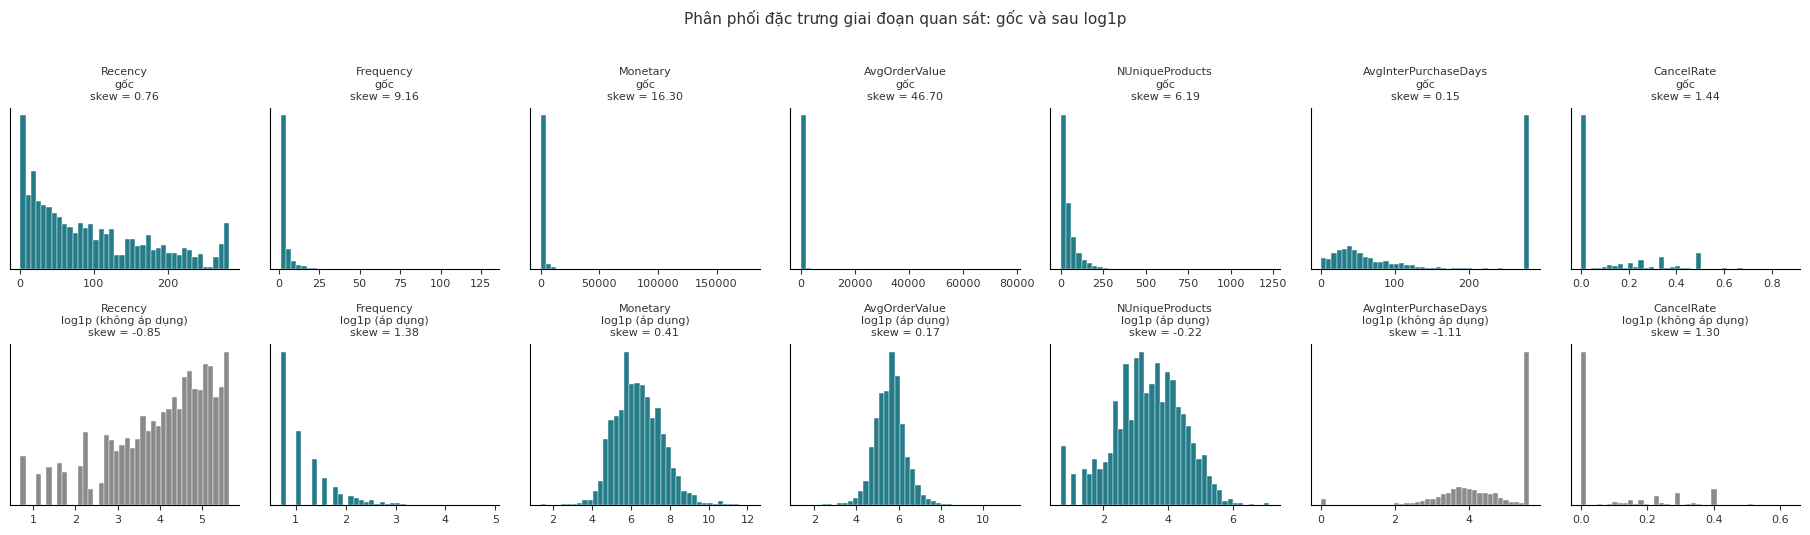

RFM | log1p cho: ['Frequency', 'Monetary']
RFM_PLUS | log1p cho: ['Frequency', 'Monetary', 'AvgOrderValue', 'NUniqueProducts']
Skewness sau biến đổi + scale (RFM_PLUS):


,Recency,Frequency,Monetary,AvgOrderValue,NUniqueProducts,AvgInterPurchaseDays,CancelRate
skew,0.764,1.378,0.407,0.166,-0.217,0.155,1.443


In [5]:
skew = ft.skewness_report(feats, RFM_PLUS)
display(skew)
skew.to_csv(TABLES_DIR / "feature_skewness.csv", encoding="utf-8-sig")

vz.plot_skew_before_after(feats, skew, FIGURES_DIR / "feat_distribution_raw_vs_log.png")
plt.show()

# Fit scaler trên giai đoạn quan sát và lưu models/scaler_*.joblib
X_rfm = ft.transform_features(feats, RFM, fit_scaler=True)
X_plus = ft.transform_features(feats, RFM_PLUS, fit_scaler=True)

for name, X in [("RFM", X_rfm), ("RFM_PLUS", X_plus)]:
    assert np.allclose(X.mean(), 0, atol=1e-9) and np.allclose(X.std(ddof=0), 1, atol=1e-9)
    print(name, "| log1p cho:", ft.load_scaler_bundle(FEATURE_SETS[name])["log_cols"])
print("Skewness sau biến đổi + scale (RFM_PLUS):")
display(X_plus.skew().rename("skew").to_frame().T)

**Đọc kết quả.** `Monetary`, `AvgOrderValue`, `Frequency`, `NUniqueProducts` lệch phải rất mạnh (skewness từ 6 đến 47) và log1p đưa về gần đối xứng (|skew| ≲ 1,4, trong đó `Frequency` vẫn còn 1,38 vì 41% khách cùng giá trị 1). `Recency` (0,76) và `AvgInterPurchaseDays` (0,15) lệch ít hoặc gần đối xứng và log1p còn làm chúng lệch trái, nên **giữ nguyên**. Hình trên cho thấy cả hai phía để người đọc tự kiểm chứng quyết định.

Với bộ `RFM` thì `Recency` giữ nguyên, `Frequency` và `Monetary` được log1p (cùng quyết định như trong `RFM_PLUS`).

## 5. Tương quan và đặc trưng dư thừa

Tương quan tính trên **ma trận đã log1p + scale** của `RFM_PLUS`, vì đây là không gian mà thuật toán dựa trên khoảng cách thực sự nhìn thấy. Hai thước đo bổ sung cho nhau:

- **Tương quan cặp (Pearson):** phát hiện hai biến gần như trùng nhau. Ngưỡng cảnh báo |r| ≥ 0,8.
- **VIF** (Variance Inflation Factor, từ nghịch đảo ma trận tương quan): phát hiện một biến bị *tổ hợp* của nhiều biến khác tái tạo mà không cặp nào cao. VIF > 10 là dư thừa nặng.

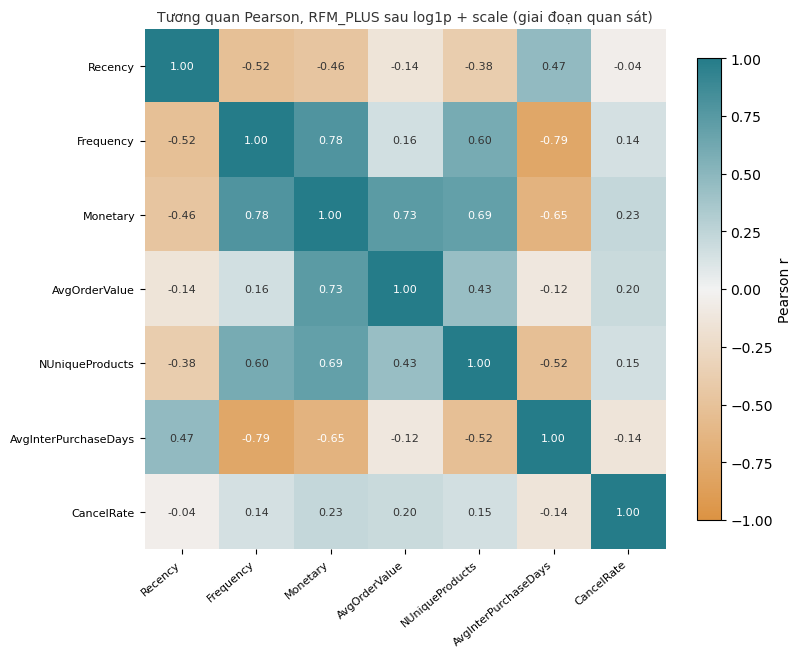

,feature_a,feature_b,pearson_r,abs_r,flag
0,Frequency,AvgInterPurchaseDays,-0.786,0.786,False
1,Frequency,Monetary,0.785,0.785,False
2,Monetary,AvgOrderValue,0.733,0.733,False
3,Monetary,NUniqueProducts,0.688,0.688,False
4,Monetary,AvgInterPurchaseDays,-0.651,0.651,False
5,Frequency,NUniqueProducts,0.598,0.598,False


Số cặp vượt ngưỡng |r| >= 0,8: 0


,VIF,max_abs_r
Monetary,766.626,0.785
AvgOrderValue,297.016,0.733
Frequency,276.208,0.786
AvgInterPurchaseDays,10.404,0.786
NUniqueProducts,1.965,0.688
Recency,1.526,0.521
CancelRate,1.063,0.226


R^2 của log Monetary theo log Frequency + log AvgOrderValue = 0.9945


In [6]:
corr = X_plus.corr()
corr.to_csv(TABLES_DIR / "feature_correlation.csv", encoding="utf-8-sig")
vz.plot_corr_heatmap(corr, "Tương quan Pearson, RFM_PLUS sau log1p + scale (giai đoạn quan sát)",
                     FIGURES_DIR / "feat_correlation_heatmap.png")
plt.show()

pairs = ft.correlation_pairs(corr, threshold=0.8)
display(pairs.head(6))
print("Số cặp vượt ngưỡng |r| >= 0,8:", int(pairs.flag.sum()))

vif = ft.vif_table(X_plus)
r2_m = ft.explained_by(X_plus, "Monetary", ["Frequency", "AvgOrderValue"])
redundancy = pd.DataFrame({"VIF": vif, "max_abs_r": corr.abs().where(~np.eye(len(corr), dtype=bool)).max()})
redundancy.to_csv(TABLES_DIR / "feature_redundancy.csv", encoding="utf-8-sig")
display(redundancy.sort_values("VIF", ascending=False))
print(f"R^2 của log Monetary theo log Frequency + log AvgOrderValue = {r2_m:.4f}")

**Phát hiện chính.** Không cặp nào vượt ngưỡng 0,8 (cao nhất: `Frequency`–`AvgInterPurchaseDays` ≈ −0,79 và `Frequency`–`Monetary` ≈ 0,79) nên *chỉ nhìn tương quan cặp sẽ kết luận không có dư thừa*. Nhưng VIF của `Monetary`, `AvgOrderValue` và `Frequency` lần lượt vào khoảng 767, 297 và 276, và hồi quy cho R² ≈ 0,995: vì `Monetary = Frequency × AvgOrderValue` theo định nghĩa, trong không gian log ta có xấp xỉ `log Monetary ≈ log Frequency + log AvgOrderValue`. Ba biến này gần như phụ thuộc tuyến tính hoàn toàn. `AvgInterPurchaseDays` có VIF ≈ 10, một phần do cách điền khách mua 1 lần (mục 3). Các biến còn lại (`Recency`, `NUniqueProducts`, `CancelRate`) gần như độc lập (VIF < 2).

**Quyết định: giữ nguyên cả 7 cột của `RFM_PLUS`, không loại biến nào, nhưng ghi rõ rủi ro.**

- Hai bộ đặc trưng được cố định trong proposal và `src/config.py`; việc so sánh `RFM` với `RFM_PLUS` là một phần câu hỏi nghiên cứu, nên mình không tự đổi định nghĩa bộ.
- Đồng tuyến **không làm hỏng** K-Means/Ward/DBSCAN về mặt toán học (ma trận khoảng cách vẫn xác định), nhưng nó **đổi trọng số**: ba trong bảy chiều cùng mô tả "quy mô chi tiêu", nên khoảng cách Euclid trong `RFM_PLUS` nghiêng nhiều về trục này và các cụm `RFM_PLUS` có thể chủ yếu tách theo mức chi tiêu thay vì thêm thông tin hành vi mới.
- **Việc cần làm ở tuần 3** (ghi để người chạy mô hình không bỏ sót): chạy thêm một phép kiểm tra độ nhạy trên `RFM_PLUS` bỏ `Monetary` (hoặc bỏ `AvgOrderValue`) và so ARI với kết quả đầy đủ. Nếu ARI cao, cụm ổn định trước loại biến; nếu thấp, kết quả `RFM_PLUS` đang bị chi phối bởi đồng tuyến và phải nói rõ trong báo cáo.

Ma trận tương quan, VIF và cặp tương quan đã lưu ở `reports/tables/feature_correlation.csv` và `feature_redundancy.csv`.

## 6. Baseline: phân khúc theo luật RFM

**Chấm điểm.** Mỗi khách nhận điểm R, F, M từ 1 đến 5 theo phân vị (`quintile_score`). Recency nhỏ hơn là tốt hơn nên được đảo chiều (mua gần đây nhất = 5 điểm).

**Xử lý giá trị trùng của Frequency.** 41% khách chỉ có 1 hóa đơn nên nhiều khách có Frequency giống hệt nhau. `pd.qcut` thẳng sẽ báo lỗi cạnh trùng. `rank(method="first")` thì chia ngẫu nhiên nhóm giống hệt nhau theo thứ tự `CustomerID`, tức là hai khách có hành vi y hệt nhận điểm khác nhau chỉ vì mã khách. Hạng trung bình cũng không ổn: nhóm thấp nhất chiếm 41% có hạng trung bình ≈ 0,20 nên rơi sang điểm 2 và không ai có điểm 1. Mình dùng **hạng "min"** (xếp hạng kiểu thi đấu): khách trùng giá trị luôn cùng điểm và nhóm thấp nhất luôn nhận điểm 1. Cái giá: các mức điểm của F không đều nhau (xem bảng dưới, không có khách nào điểm 2).

**Luật ghép** (áp theo thứ tự, `FM = (F + M) / 2`): dùng hai trục R ("còn hoạt động không") và FM ("giá trị và độ trung thành") để mỗi phân khúc có nghĩa kinh doanh rõ. Bộ luật phủ kín mọi tổ hợp nên không khách nào bị bỏ sót (có `assert`).

,Phân khúc,"Luật (R, FM = (F+M)/2)"
0,Champions,R >= 4 và FM >= 4
1,Loyal,R >= 3 và FM >= 3 (phần còn lại sau Champions)
2,Potential Loyalist,R >= 4 và 2 <= FM < 3
3,New,R >= 4 và FM < 2
4,Need Attention,R == 3 và FM < 3
5,At Risk,R <= 2 và FM >= 3
6,Hibernating,R <= 2 và 2 <= FM < 3
7,Lost,R <= 2 và FM < 2


điểm,1,2,3,4,5
chỉ số,,,,,
R,687,668,664,694,647
F,1370,0,666,655,669
M,672,672,672,672,672


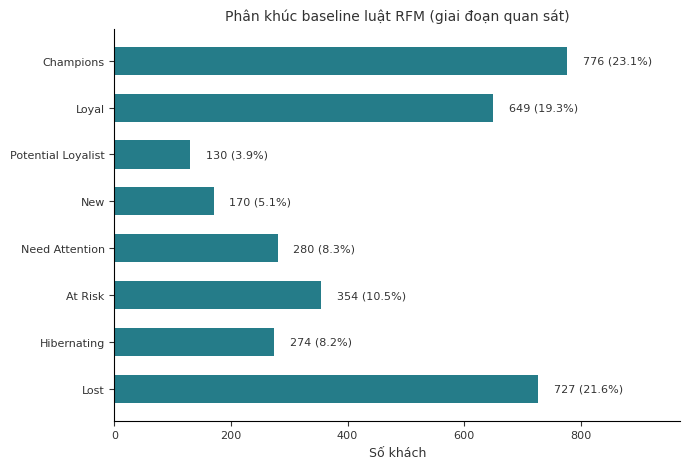

,Recency,Frequency,Monetary,n_customers
Segment,,,,
Champions,17.000,6.000,"2,135.685",776
Loyal,57.000,3.000,734.130,649
Potential Loyalist,23.000,1.000,414.300,130
New,24.000,1.000,199.185,170
Need Attention,78.000,1.000,255.650,280
At Risk,135.500,2.000,861.100,354
Hibernating,169.500,1.000,451.770,274
Lost,186.000,1.000,193.000,727


In [7]:
seg = bl.rfm_rule_segments(feats)
assert seg.index.equals(feats.index) and seg.Segment.isin(bl.SEGMENT_ORDER).all()

display(pd.DataFrame(bl.SEGMENT_RULES, columns=["Phân khúc", "Luật (R, FM = (F+M)/2)"]))
display(pd.DataFrame({c: seg[c].value_counts().sort_index() for c in "RFM"}).fillna(0).astype(int)
        .rename_axis("điểm").T.rename_axis("chỉ số"))

counts = seg.Segment.value_counts().reindex(bl.SEGMENT_ORDER)
vz.plot_segment_sizes(counts, FIGURES_DIR / "base_segment_sizes.png")
plt.show()

profile = (feats[RFM].join(seg.Segment).groupby("Segment")[RFM].median().reindex(bl.SEGMENT_ORDER)
           .join(counts.rename("n_customers")))
display(profile)
# Kiểm tra hợp lý chỉ trên đặc trưng quan sát (không dùng nhãn kiểm chứng)
assert profile.loc["Champions", "Recency"] < profile.loc["Lost", "Recency"]
assert profile.loc["Champions", "Frequency"] > profile.loc["Lost", "Frequency"]
assert profile.loc["Champions", "Monetary"] > profile.loc["Lost", "Monetary"]

seg.to_csv(DATA_PROCESSED / "labels_baseline.csv")

**Đọc kết quả.** Hồ sơ trung vị khớp với tên gọi: `Champions` mua gần đây, nhiều hóa đơn và chi tiêu cao; `Lost` ngược lại. Phân khúc nhỏ nhất là `Potential Loyalist` và `New`, vì phải vừa mua rất gần đây vừa có giá trị thấp. Cần nói rõ hạn chế của baseline này để so sánh công bằng ở tuần 3:

- **Số phân khúc (8) do người đặt luật**, không do dữ liệu. Nó trả lời "chia theo cách quen thuộc của marketing" chứ chưa trả lời RQ1.
- Ranh giới phân vị cắt giữa vùng dữ liệu dày đặc, nên khách ở hai bên ranh giới có thể gần nhau hơn khách cùng phân khúc. Điều này dự báo Silhouette thấp ở mục 7.
- Baseline chỉ dùng R, F, M nên khi đo trong không gian `RFM_PLUS` nó không biết gì về bốn biến thêm vào.

## 7. Metric nội tại của baseline (cùng hàm sẽ dùng cho mô hình học máy)

Để tuần sau so sánh công bằng, baseline được đo bằng **đúng hàm `internal_metrics`** (Silhouette, Davies–Bouldin, Calinski–Harabasz) trên **đúng ma trận đã scale** của từng bộ đặc trưng, tính trên toàn bộ điểm (không lấy mẫu, nên kết quả xác định). Kết quả lưu theo schema `TUNING_SCHEMA` để gộp trực tiếp vào bảng tuning; `inertia` để trống vì chỉ định nghĩa cho K-Means, `noise_frac = 0` vì luật gán mọi khách vào một phân khúc.

Hướng của từng metric: Silhouette càng **cao** càng tốt (−1 đến 1); Davies–Bouldin càng **thấp** càng tốt; Calinski–Harabasz càng **cao** càng tốt. Cần hai lưu ý khi đọc:

- **Không so metric giữa hai không gian đặc trưng** (3 chiều và 7 chiều có thang metric khác nhau, đặc biệt Calinski–Harabasz phụ thuộc số chiều); chỉ so các mô hình **trong cùng** bộ đặc trưng.
- Để biết số Silhouette này lớn hay nhỏ, mình đo thêm một **mốc tham chiếu**: cùng số khách mỗi phân khúc nhưng nhãn bị xáo ngẫu nhiên (`SEED = 42`). Mốc này không lưu vào bảng, chỉ để diễn giải.

In [8]:
base_metrics = bl.evaluate_baseline(feats, seg)
assert list(base_metrics.columns) == TUNING_SCHEMA
base_metrics.to_csv(TABLES_DIR / "baseline_metrics.csv", index=False, encoding="utf-8-sig")
display(base_metrics)

# Mốc tham chiếu: nhãn xáo ngẫu nhiên, giữ nguyên kích thước các phân khúc
rng = np.random.default_rng(SEED)
shuffled = pd.Series(rng.permutation(seg.Baseline_Label.to_numpy()), index=seg.index)
ref_rows = []
for name, cols in FEATURE_SETS.items():
    X = ft.transform_features(feats, cols, fit_scaler=False)
    ref_rows.append({"feature_set": name, **bl.internal_metrics(X, shuffled)})
display(pd.DataFrame(ref_rows).set_index("feature_set").rename(lambda s: s + " (nhãn xáo ngẫu nhiên)"))

,algo,feature_set,params,n_clusters,noise_frac,silhouette,davies_bouldin,calinski_harabasz,inertia
0,RFM_rule,RFM,"{""scoring"": ""quintile_rank_min_ties"", ""segment...",8,0.000,0.126,1.572,"1,199.825",NaN
1,RFM_rule,RFM_PLUS,"{""scoring"": ""quintile_rank_min_ties"", ""segment...",8,0.000,0.091,2.897,471.969,NaN


,silhouette,davies_bouldin,calinski_harabasz
feature_set,,,
RFM (nhãn xáo ngẫu nhiên),-0.028,76.200,0.545
RFM_PLUS (nhãn xáo ngẫu nhiên),-0.023,56.394,0.655


**Đọc kết quả.** Baseline đạt Silhouette ≈ 0,13 trên `RFM` và ≈ 0,09 trên `RFM_PLUS`: cấu trúc cụm **yếu** (dưới 0,25 thường coi là không có cấu trúc rõ). So với mốc nhãn ngẫu nhiên (Silhouette gần 0 hoặc âm), luật RFM tách được thông tin thật, nhưng chủ yếu vì nhãn được suy ra từ chính các biến đo (R, F, M) chứ không phải vì dữ liệu tự tách thành khối. Davies–Bouldin cao hơn nhiều trên `RFM_PLUS` (≈ 2,9 so với ≈ 1,6) và Calinski–Harabasz thấp hơn: đúng như dự đoán, vì luật không biết gì về bốn biến thêm vào và các phân khúc chồng lấn nhiều hơn trong không gian bảy chiều.

**Ý nghĩa cho tuần 3:** đây là ngưỡng để mô hình học máy phải vượt, so trong cùng bộ đặc trưng. Nhưng một mô hình có Silhouette cao hơn 0,13 chưa chắc là phân khúc tốt hơn về mặt kinh doanh; cần đọc kèm hồ sơ cụm, độ ổn định (ARI) và đánh giá ngoài RQ3, đúng như yêu cầu không chọn mô hình chỉ vì metric cao nhất.

## 8. Kiểm tra tự động chống data leakage

Các `assert` dưới đây phải qua thì notebook mới chạy hết. Điểm quan trọng nhất là phép thử thực nghiệm số 4: **phá hỏng dữ liệu tương lai** (nhân 7 lần số lượng, xóa hóa đơn hủy sau `CUTOFF`) rồi dựng lại đặc trưng và scaler từ đầu. Nếu có bất kỳ đường nào để thông tin sau `CUTOFF` rò vào đặc trưng, kết quả sẽ khác. Kiểm tra mốc thời gian chỉ nói "dữ liệu đầu vào đúng khoảng"; phép thử phá hỏng nói "đầu ra không phụ thuộc vào phần tương lai".

In [9]:
# 1. Mốc thời gian của dữ liệu đầu vào
assert sales_obs.InvoiceDate.max() < cut and cancel_obs.InvoiceDate.max() < cut
assert sales_future.InvoiceDate.min() >= cut

# 2. Nhãn kiểm chứng không nằm trong đặc trưng hay trong nhãn baseline
assert not {"FutureSpend", "Returned"} & set(feats.columns)
assert not {"FutureSpend", "Returned"} & set(seg.columns)
assert set(RFM_PLUS) <= set(feats.columns)

# 3. Scaler fit đúng trên tập khách giai đoạn quan sát
for name, cols in FEATURE_SETS.items():
    assert ft.load_scaler_bundle(cols)["scaler"].n_samples_seen_ == len(feats)

# 4. Phá hỏng dữ liệu tương lai thì đặc trưng và đặc trưng đã scale phải y hệt
assert ft.assert_no_leakage(sales, cancel, CUTOFF, REF_DATE)

# 5. Ba bảng dùng chung một tập khách, đúng thứ tự
assert feats.index.equals(outcome.index) and feats.index.equals(seg.index)

# 6. Đủ file đầu ra
expected = [DATA_PROCESSED / f for f in ("features_obs.csv", "future_outcome.csv", "labels_baseline.csv")]
expected += [TABLES_DIR / "baseline_metrics.csv", MODELS_DIR / "scaler_rfm.joblib", MODELS_DIR / "scaler_rfm_plus.joblib"]
missing = [str(p.relative_to(ROOT)) for p in expected if not p.exists()]
assert not missing, missing
print("Mọi kiểm tra leakage đều qua. File đầu ra:")
for p in expected:
    print(" -", p.relative_to(ROOT))

Mọi kiểm tra leakage đều qua. File đầu ra:
 - data\processed\features_obs.csv
 - data\processed\future_outcome.csv
 - data\processed\labels_baseline.csv
 - reports\tables\baseline_metrics.csv
 - models\scaler_rfm.joblib
 - models\scaler_rfm_plus.joblib


## 9. Tóm tắt và bàn giao cho tuần 3

**Kết quả:** 3.360 khách trong tập phân khúc; hai bộ đặc trưng đã scale; baseline 8 phân khúc; metric nội tại của baseline trên cả hai bộ đặc trưng.

**Cách dùng ở tuần sau** (đều trong `src/`):

```python
from src import features as ft, baseline as bl
from src.config import RFM, RFM_PLUS
feats = pd.read_csv(DATA_PROCESSED / "features_obs.csv", index_col="CustomerID")
X = ft.transform_features(feats, RFM_PLUS, fit_scaler=False)   # nạp scaler đã fit, không fit lại
bl.internal_metrics(X, labels)                                  # cùng hàm metric với baseline
```

Đánh giá ngoài (RQ3) đọc `data/processed/future_outcome.csv`, chỉ sau khi đã chốt mô hình.

**Hạn chế đã biết:**

- `Monetary`, `AvgOrderValue`, `Frequency` gần như đồng tuyến trong không gian log (mục 5); tuần 3 cần chạy kiểm tra độ nhạy bỏ `Monetary`.
- 41% khách chỉ mua một lần và nhận giá trị điền cho `AvgInterPurchaseDays` (mục 3); nên đối chiếu với cột `SinglePurchase` khi đọc hồ sơ cụm.
- Chỉ một lần chia thời gian tại `CUTOFF` nên chưa biết kết quả nhạy với mốc cắt đến đâu.
- Khách mới sau `CUTOFF` và khách chỉ có hóa đơn hủy không được phân khúc; RQ3 chỉ nói về khách đã có lịch sử mua.